# Bayes localisation in one dimension

How does a robot that cannot see where it is work out where it is?

This notebook builds a discrete Bayes filter (also called a histogram filter) from scratch with numpy, then tests it by simulation. It follows the standard textbook method (Thrun, Burgard and Fox, *Probabilistic Robotics*, chapter 4). It is a learning project, not new research. Every step is written out so it can be checked by hand.

**Contents**

1. Bayes' rule on three cells, checked against a hand calculation
2. Sensing and moving on a loop of 10 cells
3. A 20 m corridor with a noisy range sensor and noisy motion
4. Does the filter know how uncertain it is? A calibration check
5. Limits and what I would do next

Only `numpy` and `matplotlib` are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def entropy(p):
    # Shannon entropy in nats. 0 means certain, ln(N) means completely unsure over N cells.
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())

## 1. Bayes' rule on three cells

A robot is in one of three cells: wall, door, wall. It does not know which, so it starts with equal belief in each, 1/3. Its door sensor is right 80% of the time and wrong 20% of the time. It reads "door".

Bayes' rule says: P(cell | reading) is proportional to P(reading | cell) × P(cell).

By hand:

- Only the middle cell is a door, so the chance of reading "door" is 0.2, 0.8, 0.2 in the three cells.
- Multiply by the prior of 1/3 each: 0.2/3, 0.8/3, 0.2/3.
- These add up to 1.2/3, so divide by that to make them sum to 1: **1/6, 2/3, 1/6**.

The code below should agree.

In [2]:
world3 = np.array(["wall", "door", "wall"])
belief3 = np.full(3, 1 / 3)

def sense_discrete(belief, world, reading, p_correct):
    # Likelihood of the reading in each cell: p_correct if the cell matches, else 1 - p_correct.
    likelihood = np.where(world == reading, p_correct, 1 - p_correct)
    posterior = likelihood * belief          # Bayes' rule, unnormalised
    return posterior / posterior.sum()       # normalise so the belief sums to 1

after_one = sense_discrete(belief3, world3, "door", 0.8)
print("after one 'door' reading :", np.round(after_one, 4))
assert np.allclose(after_one, [1 / 6, 2 / 3, 1 / 6])      # matches the hand calculation

after_two = sense_discrete(after_one, world3, "door", 0.8)
print("after a second reading   :", np.round(after_two, 4))
# By hand: [0.2/6, 0.8*2/3, 0.2/6] = [0.0333, 0.5333, 0.0333]; they sum to 0.6, so divide: [0.0556, 0.8889, 0.0556]
assert np.allclose(after_two, [1 / 18, 8 / 9, 1 / 18])

after one 'door' reading : [0.1667 0.6667 0.1667]
after a second reading   : [0.0556 0.8889 0.0556]


Two agreeing readings take the belief in the middle cell from 0.33 to 0.67 to 0.89. Each reading is only 80% reliable, but they add up.

## 2. Sensing and moving on a loop of 10 cells

Now the robot moves. A move **blurs** the belief, because the robot sometimes undershoots or overshoots. This uses the Markov assumption: where the robot ends up depends only on where it is now and the command, not on its earlier history. So the move update is a weighted sum of shifted copies of the belief.

The rule used here: the robot is told to move one cell. It does so with probability 0.8, stays put with probability 0.1 (undershoot) and moves two cells with probability 0.1 (overshoot). The world is a loop, so shifting wraps around.

Sensing sharpens the belief and moving blurs it. The filter alternates the two.

one certain cell after a move: [0.  0.  0.  0.1 0.8 0.1 0.  0.  0.  0. ]
true cells: [3, 4, 5, 6, 7, 8, 9, 0, 2, 3, 4, 6, 7, 8, 9, 0, 1, 3, 4, 5]
readings  : ['W', 'W', 'W', 'D', 'W', 'W', 'W', 'W', 'W', 'W', 'D', 'D', 'D', 'W', 'W', 'W', 'D', 'W', 'D', 'W']


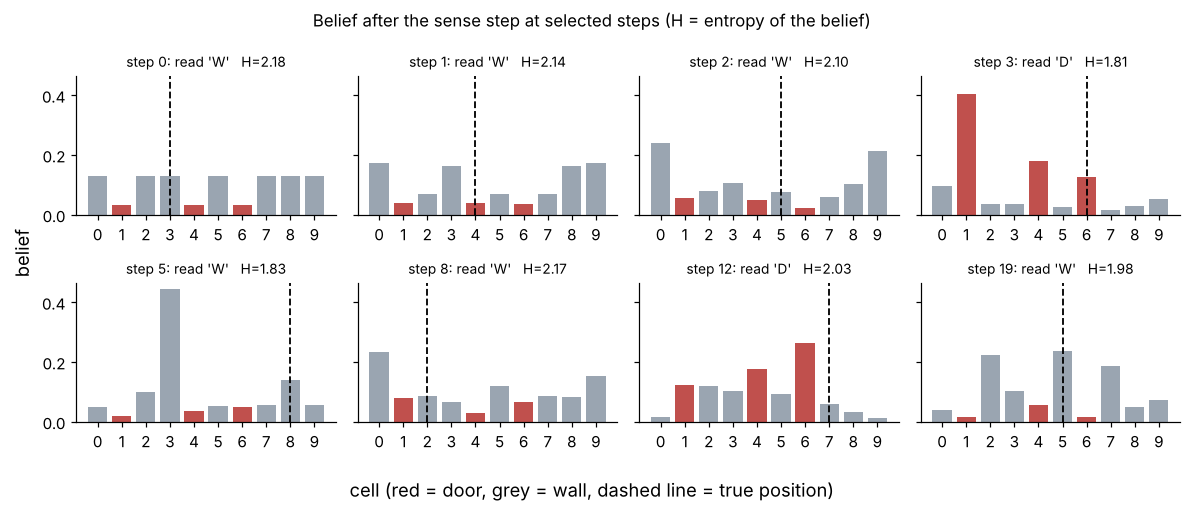

maximum possible entropy (no idea at all): 2.30


best guess equals the true cell at steps 0, 3, 6, 10, 19: [0.12 0.34 0.34 0.37 0.35] (chance = 0.10)


In [3]:
world10 = np.array(list("WDWWDWDWWW"))       # W = wall, D = door; doors at cells 1, 4 and 6
N10 = len(world10)

def move_discrete(belief, p_exact=0.8, p_under=0.1, p_over=0.1, step=1):
    # np.roll shifts the belief by a number of cells (wrapping around the loop)
    return (p_exact * np.roll(belief, step)
            + p_under * np.roll(belief, step - 1)
            + p_over * np.roll(belief, step + 1))

# Sanity checks: a move conserves probability, and blurs a certain belief into three cells
spike = np.zeros(N10); spike[3] = 1
moved = move_discrete(spike)
assert np.isclose(moved.sum(), 1)
print("one certain cell after a move:", np.round(moved, 2))

def simulate_discrete(rng, T=20, start=3, p_sense=0.8):
    # Generate what the robot actually does and reads. The filter below only sees the readings.
    pos, truth, readings = start, [], []
    for _ in range(T):
        correct = str(world10[pos])
        wrong = "W" if correct == "D" else "D"
        readings.append(correct if rng.random() < p_sense else wrong)
        truth.append(int(pos))
        pos = int((pos + rng.choice([1, 0, 2], p=[0.8, 0.1, 0.1])) % N10)
    return truth, readings

rng = np.random.default_rng(3)
truth10, readings10 = simulate_discrete(rng)
print("true cells:", truth10)
print("readings  :", readings10)

belief = np.full(N10, 1 / N10)
beliefs10 = []
for z in readings10:
    belief = sense_discrete(belief, world10, z, 0.8)
    beliefs10.append(belief.copy())
    belief = move_discrete(belief)

show = [0, 1, 2, 3, 5, 8, 12, 19]                    # steps to draw
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for t, ax in zip(show, axes.ravel()):
    b = beliefs10[t]
    colours = ["#c0504d" if world10[i] == "D" else "#9aa5b1" for i in range(N10)]
    ax.bar(range(N10), b, color=colours)
    ax.axvline(truth10[t], color="black", lw=1.2, ls="--")
    ax.set_title(f"step {t}: read '{readings10[t]}'   H={entropy(b):.2f}", fontsize=9)
    ax.set_xticks(range(N10))
fig.supxlabel("cell (red = door, grey = wall, dashed line = true position)")
fig.supylabel("belief")
fig.suptitle("Belief after the sense step at selected steps (H = entropy of the belief)", fontsize=11)
fig.tight_layout()
fig.savefig("figures/discrete_filter.png", dpi=130)
plt.show()
print("maximum possible entropy (no idea at all): %.2f" % np.log(N10))

# How often is the single most probable cell the true cell? 300 runs, random starting cells.
hits = np.zeros(20)
for s in range(300):
    r = np.random.default_rng(1000 + s)
    tr, rd = simulate_discrete(r, T=20, start=int(r.integers(N10)))
    b = np.full(N10, 1 / N10)
    for t, z in enumerate(rd):
        b = sense_discrete(b, world10, z, 0.8)
        hits[t] += (b.argmax() == tr[t])
        b = move_discrete(b)
hits /= 300
print("best guess equals the true cell at steps 0, 3, 6, 10, 19:", np.round(hits[[0, 3, 6, 10, 19]], 2), "(chance = 0.10)")

**What to notice.** The belief piles up on and near doors, but it never collapses onto one cell, and the entropy stalls. Two things cause that. Every move adds uncertainty (one move in five is off by a cell), and a door/wall reading carries little information because seven of the ten cells look like "wall". Averaged over 300 runs, the most probable cell is the true cell only about a third of the time (35% at step 19), against a chance level of 10%. That is a limit of this sensor and this map, not a bug. Section 3 uses a better sensor and the same filter locks on.

## 3. A 20 m corridor with a noisy range sensor and noisy motion

Same idea, now closer to a real sensor. Position is a grid of 0.1 m cells across 20 m (201 cells), and the robot is free to be anywhere at the start.

- **Map:** five landmarks at known positions.
- **Sensor:** reports the signed distance to the *nearest* landmark, with Gaussian noise (standard deviation 0.25 m). It does not say which landmark it saw.
- **Motion:** each command is 0.5 m forward, executed with Gaussian error (standard deviation 0.15 m). The robot stops at the corridor ends.

Because the sensor cannot say which landmark it is looking at, early beliefs have several peaks. Moving separates them, because the landmark spacings differ.

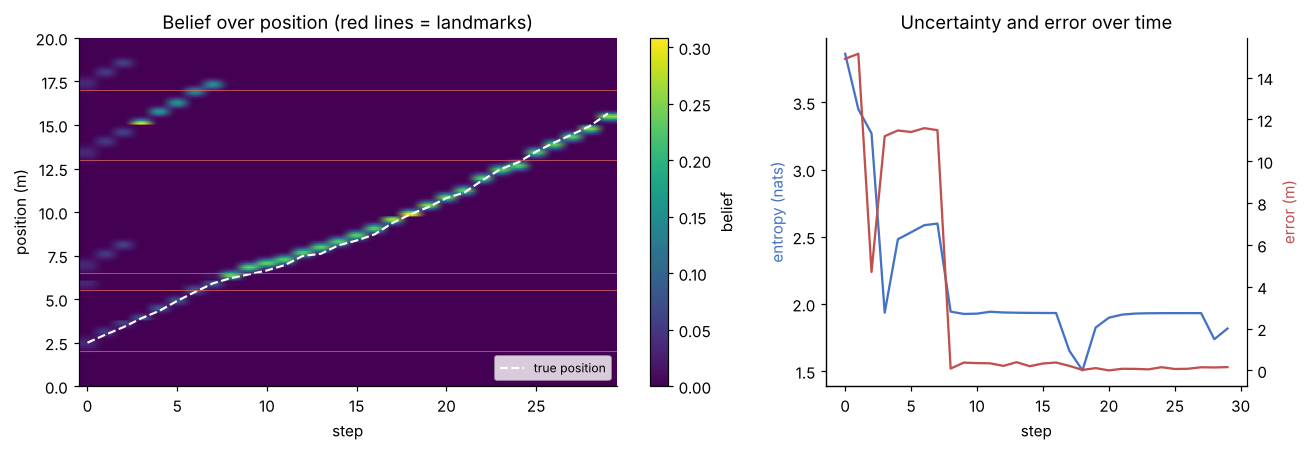

entropy after the first reading: 3.86 nats (no idea at all would be 5.30)
first step with >90% of belief within 0.5 m of the best guess: step 8
error at the last step: 0.16 m (true 15.66 m, estimate 15.50 m)


In [4]:
L, dx = 20.0, 0.1
xs = np.arange(0, L + dx / 2, dx)                  # cell centres, 201 of them
N = len(xs)
landmarks = np.array([2.0, 5.5, 6.5, 13.0, 17.0])  # known map (metres)
SIGMA_S_TRUE, SIGMA_M_TRUE, STEP = 0.25, 0.15, 0.5

def range_to_nearest(x):
    # Signed distance from position(s) x to the nearest landmark
    x = np.atleast_1d(x)
    d = landmarks[None, :] - x[:, None]
    nearest = np.abs(d).argmin(axis=1)
    return d[np.arange(len(x)), nearest]

expected_z = range_to_nearest(xs)    # what a perfect sensor would read in every cell

def gaussian(z, mu, sigma):
    return np.exp(-0.5 * ((z - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

def sense_range(belief, z, sigma_s):
    # Bayes' rule again: likelihood of reading z in each cell, times the prior belief
    posterior = gaussian(z, expected_z, sigma_s) * belief
    total = posterior.sum()
    assert total > 0, "reading is impossible under this model"
    return posterior / total

def move_range(belief, u, sigma_m):
    # Spread each cell's belief over the cells it might end up in, using a Gaussian on the move
    half = int(np.ceil(5 * sigma_m / dx))
    centre = int(round(u / dx))
    ks = np.arange(centre - half, centre + half + 1)        # possible moves, in cells
    w = gaussian(ks * dx, u, sigma_m)
    w /= w.sum()
    new = np.zeros_like(belief)
    idx = np.arange(N)
    for k, wk in zip(ks, w):
        np.add.at(new, np.clip(idx + k, 0, N - 1), belief * wk)   # clip: the robot cannot leave the corridor
    return new

def simulate_run(rng, T=30):
    # The robot's true path and the noisy readings it would collect along it
    x = rng.uniform(0.0, 4.0)
    xs_true, zs = [], []
    for _ in range(T):
        xs_true.append(x)
        zs.append(range_to_nearest(x)[0] + rng.normal(0, SIGMA_S_TRUE))
        x = float(np.clip(x + STEP + rng.normal(0, SIGMA_M_TRUE), 0, L))
    return np.array(xs_true), np.array(zs)

def run_filter(zs, sigma_s, sigma_m):
    # Sense, then move, at every step. Returns the belief after each sense step.
    belief = np.full(N, 1 / N)
    out = []
    for z in zs:
        belief = sense_range(belief, z, sigma_s)
        out.append(belief.copy())
        belief = move_range(belief, STEP, sigma_m)
    return np.array(out)

# One demonstration run
rng = np.random.default_rng(7)
x_true, zs = simulate_run(rng)
B = run_filter(zs, SIGMA_S_TRUE, SIGMA_M_TRUE)

map_est = xs[B.argmax(axis=1)]                      # most probable position at each step
err = map_est - x_true
H = np.array([entropy(b) for b in B])
mass_near = np.array([b[np.abs(xs - m) <= 0.5].sum() for b, m in zip(B, map_est)])
first_confident = int(np.argmax(mass_near > 0.9))   # first step with >90% belief within 0.5 m of the best guess

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
im = ax1.imshow(B.T, origin="lower", aspect="auto", extent=[-0.5, len(zs) - 0.5, 0, L], cmap="viridis")
ax1.plot(range(len(zs)), x_true, "w--", lw=1.4, label="true position")
for lm in landmarks:
    ax1.axhline(lm, color="#e06666", lw=0.6, alpha=0.8)
ax1.set_xlabel("step"); ax1.set_ylabel("position (m)")
ax1.set_title("Belief over position (red lines = landmarks)")
ax1.legend(loc="lower right", fontsize=8)
fig.colorbar(im, ax=ax1, label="belief")
ax2.plot(H, color="#4472c4", label="entropy of belief")
ax2.set_xlabel("step"); ax2.set_ylabel("entropy (nats)", color="#4472c4")
ax2b = ax2.twinx()
ax2b.plot(np.abs(err), color="#c0504d", label="|best guess - truth|")
ax2b.set_ylabel("error (m)", color="#c0504d")
ax2b.spines["right"].set_visible(True)
ax2.set_title("Uncertainty and error over time")
fig.tight_layout()
fig.savefig("figures/range_filter.png", dpi=130)
plt.show()

print("entropy after the first reading: %.2f nats (no idea at all would be %.2f)" % (H[0], np.log(N)))
print("first step with >90%% of belief within 0.5 m of the best guess: step %d" % first_confident)
print("error at the last step: %.2f m (true %.2f m, estimate %.2f m)" % (abs(err[-1]), x_true[-1], map_est[-1]))

## 4. Does the filter know how uncertain it is?

A belief is only useful if its confidence is honest. If the filter says "90% of my belief is in this region", the truth should be inside that region about 90% of the time.

The check: simulate many runs with the true noise levels above (0.25 m sensor, 0.15 m motion). At the final step, find the smallest set of cells that holds 90% of the belief, and ask whether the true cell is inside it.

Then run the filter on the *same* simulated data but give it the **wrong** noise levels: too optimistic (it trusts its sensor and its motion more than it should) and too pessimistic. A filter that is overconfident is dangerous, because a planner will trust it.

overconfident (sensor 0.10, move 0.05)     coverage 0.533 +/- 0.029   mean 90% region width 0.24 m


matched to truth (sensor 0.25, move 0.15)  coverage 0.917 +/- 0.016   mean 90% region width 0.57 m


underconfident (sensor 0.60, move 0.40)    coverage 0.987 +/- 0.007   mean 90% region width 1.25 m


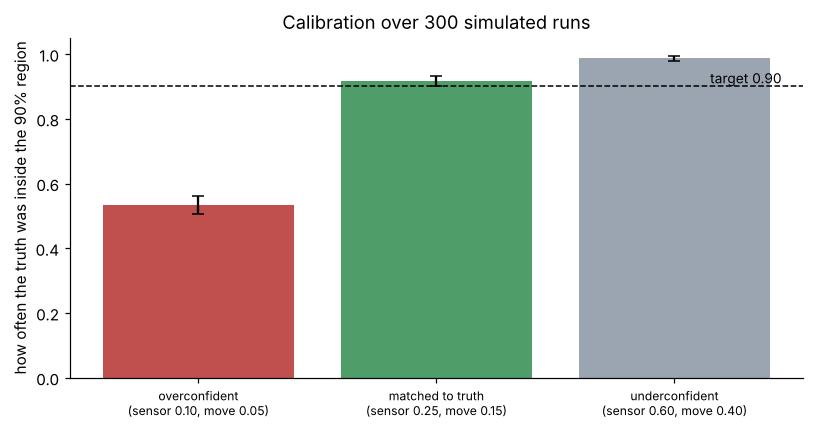

In [5]:
def credible_set(belief, level=0.9):
    # Smallest set of cells holding at least `level` of the belief (most probable cells first)
    order = np.argsort(belief)[::-1]
    k = int(np.searchsorted(np.cumsum(belief[order]), level)) + 1
    return order[:k]

n_runs = 300
rng = np.random.default_rng(11)
runs = [simulate_run(rng) for _ in range(n_runs)]    # the same data is used for every setting below

settings = {
    "overconfident\n(sensor 0.10, move 0.05)": (0.10, 0.05),
    "matched to truth\n(sensor 0.25, move 0.15)": (SIGMA_S_TRUE, SIGMA_M_TRUE),
    "underconfident\n(sensor 0.60, move 0.40)": (0.60, 0.40),
}

results = {}
for name, (ss, sm) in settings.items():
    hits, widths = [], []
    for x_true_run, zs_run in runs:
        b_final = run_filter(zs_run, ss, sm)[-1]
        cs = credible_set(b_final, 0.9)
        true_cell = int(round(x_true_run[-1] / dx))
        hits.append(true_cell in cs)
        widths.append(len(cs) * dx)
    p = float(np.mean(hits))
    results[name] = (p, float(np.sqrt(p * (1 - p) / n_runs)), float(np.mean(widths)))
    print("%-42s coverage %.3f +/- %.3f   mean 90%% region width %.2f m"
          % (name.replace("\n", " "), *results[name]))

fig, ax = plt.subplots(figsize=(7.5, 4))
names = list(results)
cov = [results[n][0] for n in names]
se = [results[n][1] for n in names]
ax.bar(range(3), cov, yerr=se, color=["#c0504d", "#4f9d69", "#9aa5b1"], capsize=4)
ax.axhline(0.9, color="black", ls="--", lw=1)
ax.text(2.45, 0.91, "target 0.90", ha="right", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("how often the truth was inside the 90% region")
ax.set_ylim(0, 1.05)
ax.set_title("Calibration over %d simulated runs" % n_runs)
fig.tight_layout()
fig.savefig("figures/calibration.png", dpi=130)
plt.show()

**What the results say.** With the right noise levels, the 90% region contained the truth about 92% of the time, as it should. When the filter was told the noise was smaller than it really is, its region was narrow (0.24 m) but contained the truth only 53% of the time: it was confidently wrong almost half the time. The pessimistic filter contained the truth 99% of the time, but its regions were more than twice as wide as the matched filter's (1.25 m against 0.57 m). That is safe but less useful. Getting the noise model right matters as much as the algorithm.

## 5. Limits and what I would do next

- **The simulation uses the noise model the filter assumes.** The matched result in section 4 is therefore a best case. I tested wrong noise *sizes*, but not non-Gaussian errors, outliers, a wrong map or a robot that is picked up and moved.
- **The map and the move commands are assumed known.** This is localisation only. The robot does not build the map.
- **A histogram filter does not scale.** 201 cells is fine in one dimension. A 20 m by 20 m area at 0.1 m resolution is 40,000 cells, and adding heading makes it millions. Particle filters and Kalman filters are what is used in practice.
- **The calibration check uses one time slice (the last step) of 300 runs.** The standard error on each coverage figure is about 1 to 3 percentage points, shown as error bars.
- **Next steps I would try:** swap in a particle filter and compare coverage and run time; run the same code on real range logs from a public robot dataset; and feed the belief into a planner that chooses moves to shrink uncertainty fastest.